# Exploratory Data Analysis — Online Retail II

## SWYNEX Technologies — Task 2

### Objective

The objective of this task is to perform Exploratory Data Analysis (EDA) on the cleaned Online Retail II dataset.

The analysis will be used to:

- Understand the structure and characteristics of the dataset.
- Analyze sales and revenue patterns.
- Identify top-performing products and countries.
- Analyze customer purchasing behavior.
- Study cancellations and returns.
- Identify trends, patterns, and potential anomalies.
- Generate meaningful business insights from the data.

### Tools Used

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn

### Dataset

The analysis uses the cleaned Online Retail II dataset prepared during Task 1.

The dataset contains transactions from an online retail business and includes information about invoices, products, quantities, prices, customers, countries, dates, and revenue.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

# Visualization style
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## 1. Load the Cleaned Dataset

The cleaned dataset generated during Task 1 will be used as the input for this analysis.

Using the cleaned dataset ensures that the EDA is performed on validated data while preserving meaningful business events such as cancellations, returns, and adjustments.

In [3]:
file_path = "../data/cleaned/online_retail_II_cleaned.csv"

df = pd.read_csv(
    file_path,
    parse_dates=["InvoiceDate"]
)

print("Dataset loaded successfully.")
print(f"Number of rows: {len(df):,}")
print(f"Number of columns: {len(df.columns)}")

Dataset loaded successfully.
Number of rows: 1,033,031
Number of columns: 16


## 2. Initial Dataset Inspection

The first few records are examined to understand how the data is structured and what information is available in each transaction.

In [4]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,IsCancellation,IsZeroPrice,TransactionType,Revenue,Year,Month,MonthName,YearMonth
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom,False,False,Sale,83.40,2009,12,December,2009-12
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,False,False,Sale,81.00,2009,12,December,2009-12
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,False,False,Sale,81.00,2009,12,December,2009-12
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom,False,False,Sale,100.80,2009,12,December,2009-12
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom,False,False,Sale,30.00,2009,12,December,2009-12


### Dataset Dimensions

The shape of the dataset is checked to confirm the number of observations and variables available for analysis.

In [5]:
rows, columns = df.shape

print(f"Rows    : {rows:,}")
print(f"Columns : {columns}")

Rows    : 1,033,031
Columns : 16


### Column Information

The column names are examined to understand the variables available for the exploratory analysis.

In [6]:
print("Columns in the dataset:\n")

for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")

Columns in the dataset:

1. Invoice
2. StockCode
3. Description
4. Quantity
5. InvoiceDate
6. Price
7. Customer ID
8. Country
9. IsCancellation
10. IsZeroPrice
11. TransactionType
12. Revenue
13. Year
14. Month
15. MonthName
16. YearMonth


## 3. Data Types

Checking data types helps ensure that each variable is stored in an appropriate format for analysis.

In [7]:
df.dtypes

Invoice                       str
StockCode                     str
Description                   str
Quantity                    int64
InvoiceDate        datetime64[us]
Price                     float64
Customer ID               float64
Country                       str
IsCancellation               bool
IsZeroPrice                  bool
TransactionType               str
Revenue                   float64
Year                        int64
Month                       int64
MonthName                     str
YearMonth                     str
dtype: object

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1033031 entries, 0 to 1033030
Data columns (total 16 columns):
 #   Column           Non-Null Count    Dtype         
---  ------           --------------    -----         
 0   Invoice          1033031 non-null  str           
 1   StockCode        1033031 non-null  str           
 2   Description      1032668 non-null  str           
 3   Quantity         1033031 non-null  int64         
 4   InvoiceDate      1033031 non-null  datetime64[us]
 5   Price            1033031 non-null  float64       
 6   Customer ID      797885 non-null   float64       
 7   Country          1033031 non-null  str           
 8   IsCancellation   1033031 non-null  bool          
 9   IsZeroPrice      1033031 non-null  bool          
 10  TransactionType  1033031 non-null  str           
 11  Revenue          1033031 non-null  float64       
 12  Year             1033031 non-null  int64         
 13  Month            1033031 non-null  int64         
 14  MonthName    

## 4. Missing Value Analysis

Missing values are examined to understand whether any variables contain incomplete information.

Missing values are not automatically removed because some missing fields, particularly Customer ID, may still contain useful transaction-level information.

In [9]:
missing_values = df.isnull().sum()

missing_percentage = (missing_values / len(df)) * 100

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage
})

missing_summary = missing_summary[
    missing_summary["Missing Values"] > 0
].sort_values(
    "Missing Values",
    ascending=False
)

missing_summary

,Missing Values,Missing Percentage
Customer ID,235146,22.76
Description,363,0.04


## 5. Descriptive Statistics

Descriptive statistics are used to understand the central tendency, spread, and range of numerical variables such as quantity, price, and revenue.

In [10]:
df[["Quantity", "Price", "Revenue"]].describe()

,Quantity,Price,Revenue
count,"1,033,031.00","1,033,031.00","1,033,031.00"
mean,10.08,4.77,18.41
std,175.20,92.84,284.72
min,"-80,995.00",0.00,"-168,469.60"
25%,1.00,1.25,3.75
50%,3.00,2.10,9.92
75%,10.00,4.15,17.70
max,"80,995.00","38,970.00","168,469.60"


## 6. Transaction Type Analysis

The distribution of transaction types is analyzed to understand the proportion of normal sales, cancellations/returns, and operational adjustments.

In [11]:
transaction_counts = df["TransactionType"].value_counts()

transaction_counts

TransactionType
Sale                   1010534
Cancellation/Return      19104
Adjustment                3393
Name: count, dtype: int64

In [12]:
transaction_percentage = (
    df["TransactionType"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

transaction_percentage

TransactionType
Sale                  97.82
Cancellation/Return    1.85
Adjustment             0.33
Name: proportion, dtype: float64

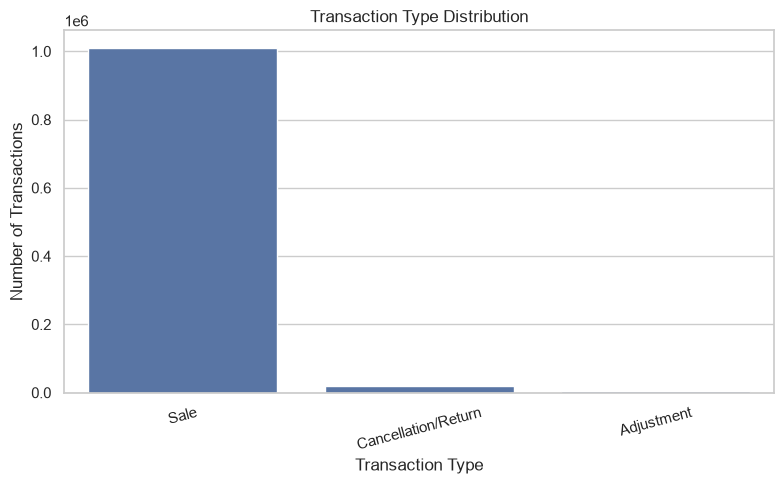

In [13]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="TransactionType"
)

plt.title("Transaction Type Distribution")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=15)
plt.tight_layout()

plt.show()

## 7. Revenue Analysis

Revenue is analyzed to understand the financial performance of the retail business.

The `Revenue` column was created during Task 1 using:

Revenue = Quantity × Price

Both positive and negative revenue values are retained because negative quantities represent cancellations, returns, or operational adjustments.

In [14]:
total_revenue = df["Revenue"].sum()

print(f"Total Revenue: £{total_revenue:,.2f}")

Total Revenue: £19,014,209.84


### Sales Revenue vs Net Revenue

To better understand business performance, normal sales revenue is compared with the overall net revenue.

Normal sales are identified using the `TransactionType` column.

In [15]:
sales_revenue = df.loc[
    df["TransactionType"] == "Sale",
    "Revenue"
].sum()

net_revenue = df["Revenue"].sum()

print(f"Sales Revenue : £{sales_revenue:,.2f}")
print(f"Net Revenue   : £{net_revenue:,.2f}")

Sales Revenue : £20,476,260.45
Net Revenue   : £19,014,209.84


In [16]:
return_adjustment_value = sales_revenue - net_revenue

print(f"Revenue reduction from returns/adjustments: £{return_adjustment_value:,.2f}")

Revenue reduction from returns/adjustments: £1,462,050.61


## 8. Yearly Revenue Analysis

Yearly revenue is analyzed to identify changes in business performance across the available years.

In [17]:
yearly_revenue = (
    df.groupby("Year")["Revenue"]
    .sum()
    .reset_index()
)

yearly_revenue

,Year,Revenue
0,2009,"796,648.50"
1,2010,"9,216,135.87"
2,2011,"9,001,425.46"


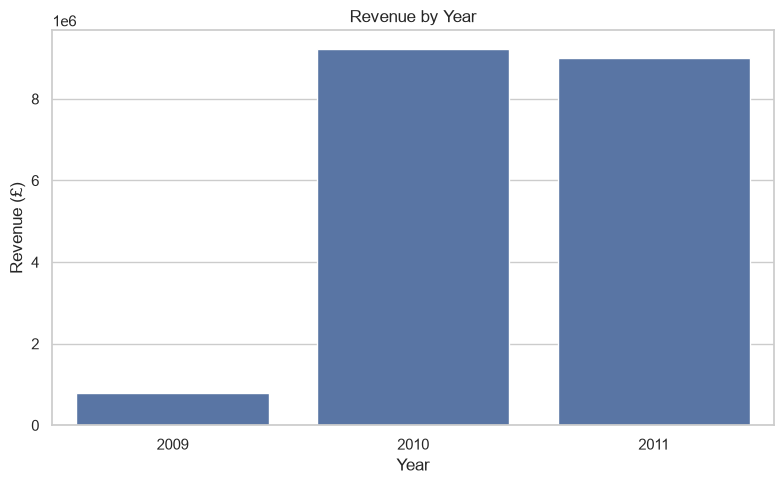

In [18]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=yearly_revenue,
    x="Year",
    y="Revenue"
)

plt.title("Revenue by Year")
plt.xlabel("Year")
plt.ylabel("Revenue (£)")
plt.tight_layout()

plt.show()

## 9. Monthly Revenue Trend

Monthly revenue is analyzed to identify seasonal patterns, growth trends, and periods of high or low business activity.

In [19]:
monthly_revenue = (
    df.groupby("YearMonth")["Revenue"]
    .sum()
    .reset_index()
)

monthly_revenue.head()

,YearMonth,Revenue
0,2009-12,"796,648.50"
1,2010-01,"622,479.50"
2,2010-02,"531,265.37"
3,2010-03,"763,247.24"
4,2010-04,"641,521.05"


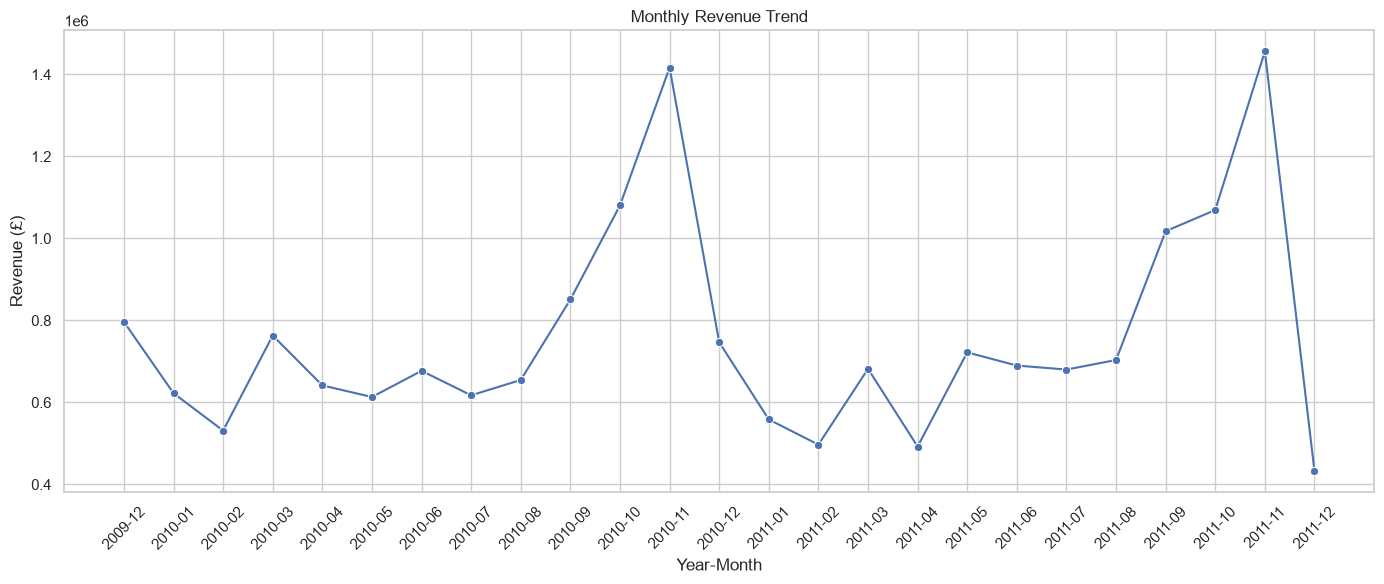

In [20]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_revenue,
    x="YearMonth",
    y="Revenue",
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Year-Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [21]:
peak_month = monthly_revenue.loc[
    monthly_revenue["Revenue"].idxmax()
]

print("Highest Revenue Month:")
print(peak_month)

Highest Revenue Month:
YearMonth        2011-11
Revenue     1,456,145.80
Name: 23, dtype: object


In [22]:
lowest_month = monthly_revenue.loc[
    monthly_revenue["Revenue"].idxmin()
]

print("Lowest Revenue Month:")
print(lowest_month)

Lowest Revenue Month:
YearMonth      2011-12
Revenue     432,719.06
Name: 24, dtype: object


## 10. Product Analysis

Products are analyzed to identify the items that contribute the most to revenue.

This helps identify high-performing products and understand product-level sales concentration.

In [23]:
top_products_revenue = (
    df.groupby(["StockCode", "Description"])["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

top_products_revenue

,StockCode,Description,Revenue
0,22423,REGENCY CAKESTAND 3 TIER,"314,045.02"
1,DOT,DOTCOM POSTAGE,"309,844.10"
2,85123A,WHITE HANGING HEART T-LIGHT HOLDER,"248,159.10"
3,47566,PARTY BUNTING,"147,079.73"
4,85099B,JUMBO BAG RED RETROSPOT,"143,834.41"
5,84879,ASSORTED COLOUR BIRD ORNAMENT,"128,550.42"
6,22086,PAPER CHAIN KIT 50'S CHRISTMAS,"116,298.59"
7,POST,POSTAGE,"110,430.41"
8,79321,CHILLI LIGHTS,"79,905.13"
9,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,"70,969.95"


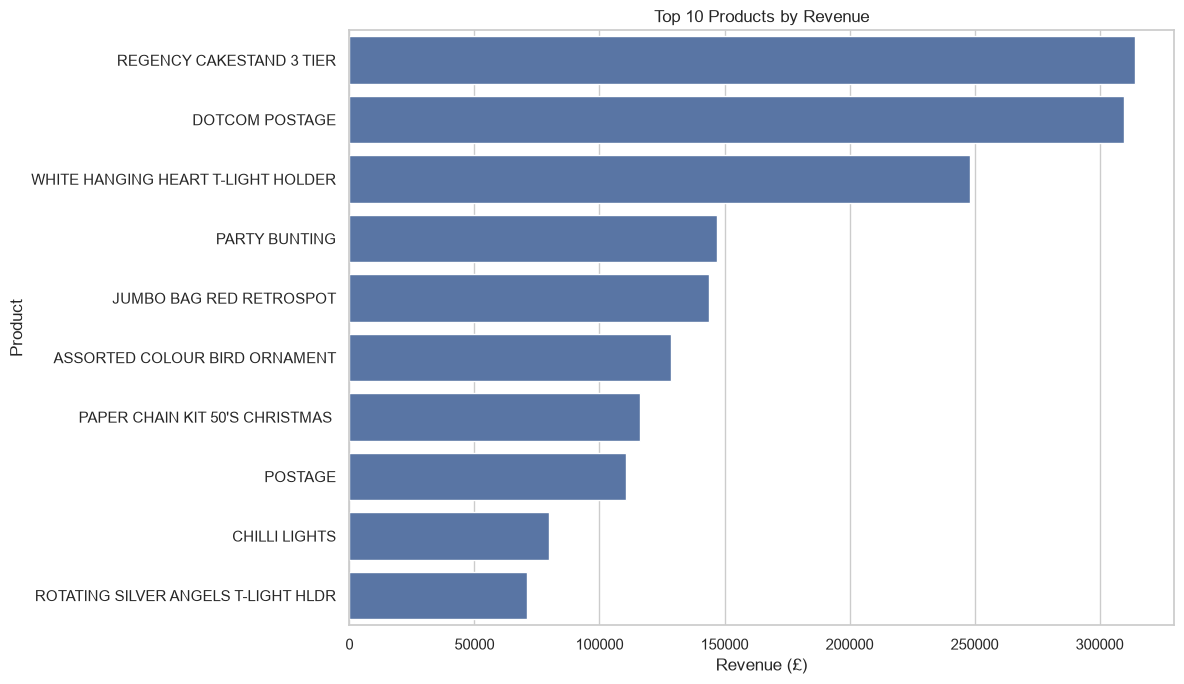

In [24]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_products_revenue,
    y="Description",
    x="Revenue"
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

### Top Products by Quantity Sold

The quantity sold is analyzed separately from revenue to identify products with the highest transaction volume.

In [25]:
top_products_quantity = (
    df[df["Quantity"] > 0]
    .groupby(["StockCode", "Description"])["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

top_products_quantity

,StockCode,Description,Quantity
0,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,106250
1,85123A,WHITE HANGING HEART T-LIGHT HOLDER,94147
2,23843,"PAPER CRAFT , LITTLE BIRDIE",80995
3,84879,ASSORTED COLOUR BIRD ORNAMENT,80090
4,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033
5,85099B,JUMBO BAG RED RETROSPOT,77286
6,17003,BROCADE RING PURSE,70379
7,21977,PACK OF 60 PINK PAISLEY CAKE CASES,56061
8,84991,60 TEATIME FAIRY CAKE CASES,54028
9,22197,SMALL POPCORN HOLDER,48597


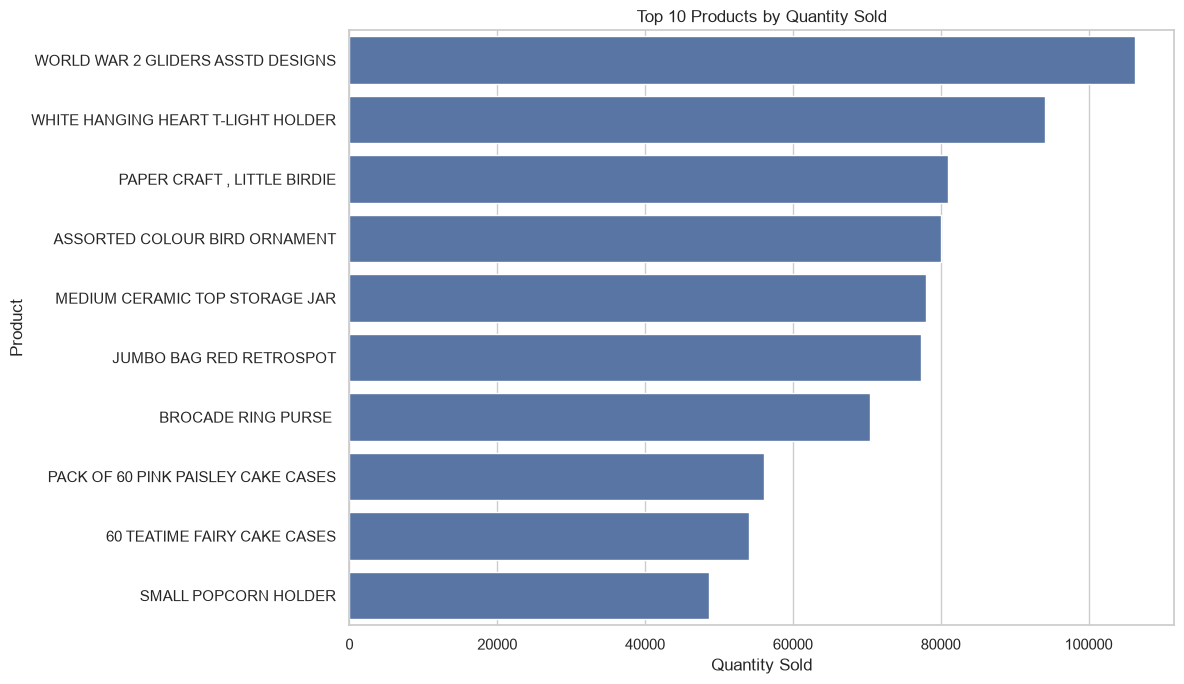

In [26]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_products_quantity,
    y="Description",
    x="Quantity"
)

plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Quantity Sold")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

In [27]:
df["Quantity"] > 0

0          True
1          True
2          True
3          True
4          True
           ... 
1033026    True
1033027    True
1033028    True
1033029    True
1033030    True
Name: Quantity, Length: 1033031, dtype: bool

## 11. Country Analysis

Country-level analysis is performed to understand the geographic distribution of transactions and revenue.

This can help identify important markets and countries contributing significantly to the business.

In [28]:
country_transactions = (
    df.groupby("Country")
    .size()
    .sort_values(ascending=False)
    .head(10)
    .reset_index(name="Transactions")
)

country_transactions

,Country,Transactions
0,United Kingdom,948316
1,EIRE,17667
2,Germany,17339
3,France,14025
4,Netherlands,5137
5,Spain,3754
6,Switzerland,3175
7,Belgium,3110
8,Portugal,2528
9,Australia,1890


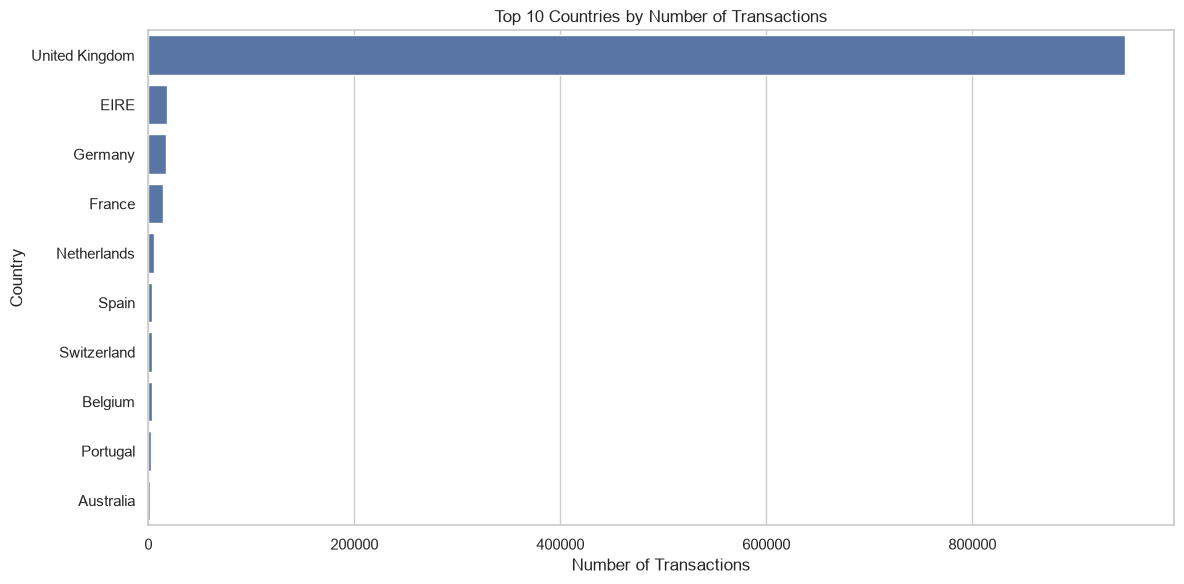

In [29]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=country_transactions,
    y="Country",
    x="Transactions"
)

plt.title("Top 10 Countries by Number of Transactions")
plt.xlabel("Number of Transactions")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

In [30]:
country_revenue = (
    df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

country_revenue

,Country,Revenue
0,United Kingdom,"16,144,736.48"
1,EIRE,"609,953.78"
2,Netherlands,"548,330.70"
3,Germany,"411,959.16"
4,France,"321,733.39"
5,Australia,"166,444.42"
6,Switzerland,"99,403.06"
7,Spain,"91,013.44"
8,Sweden,"87,775.52"
9,Denmark,"64,459.59"


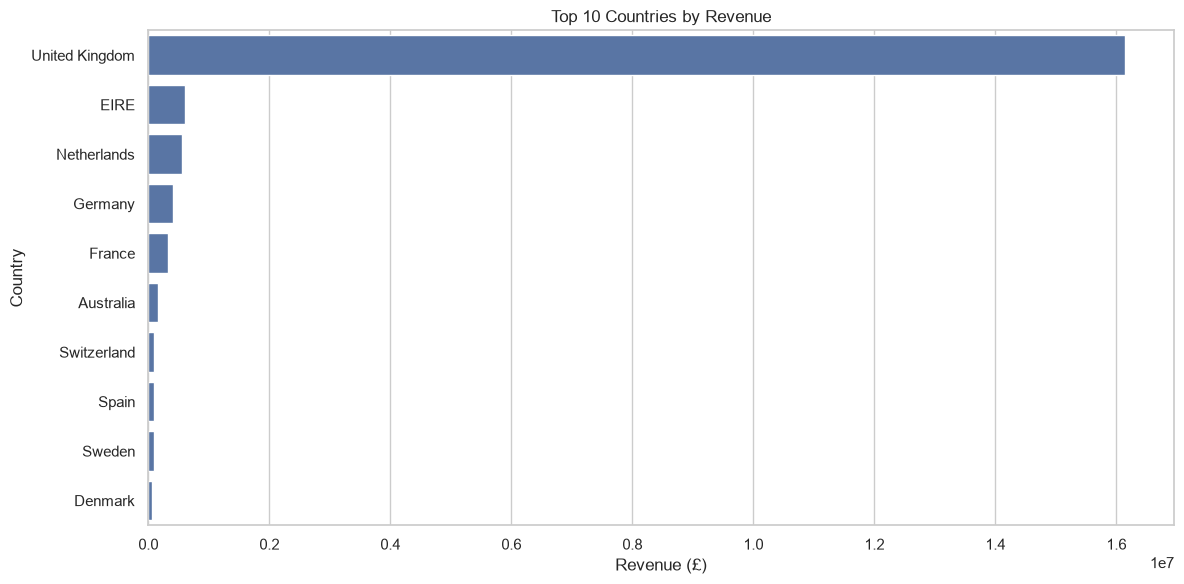

In [31]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=country_revenue,
    y="Country",
    x="Revenue"
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

## 12. Customer Analysis

Customer-level analysis is performed to identify high-value customers and understand the concentration of revenue across customers.

Transactions without a Customer ID are excluded from customer-level analysis because they cannot be attributed to a specific customer.

In [32]:
customer_revenue = (
    df.dropna(subset=["Customer ID"])
    .groupby("Customer ID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

customer_revenue

,Customer ID,Revenue
0,"18,102.00","570,380.61"
1,"14,646.00","523,342.07"
2,"14,156.00","296,063.44"
3,"14,911.00","265,757.91"
4,"17,450.00","231,390.55"
5,"13,694.00","190,020.84"
6,"17,511.00","168,491.62"
7,"12,415.00","143,269.29"
8,"16,684.00","141,502.25"
9,"15,061.00","124,961.98"


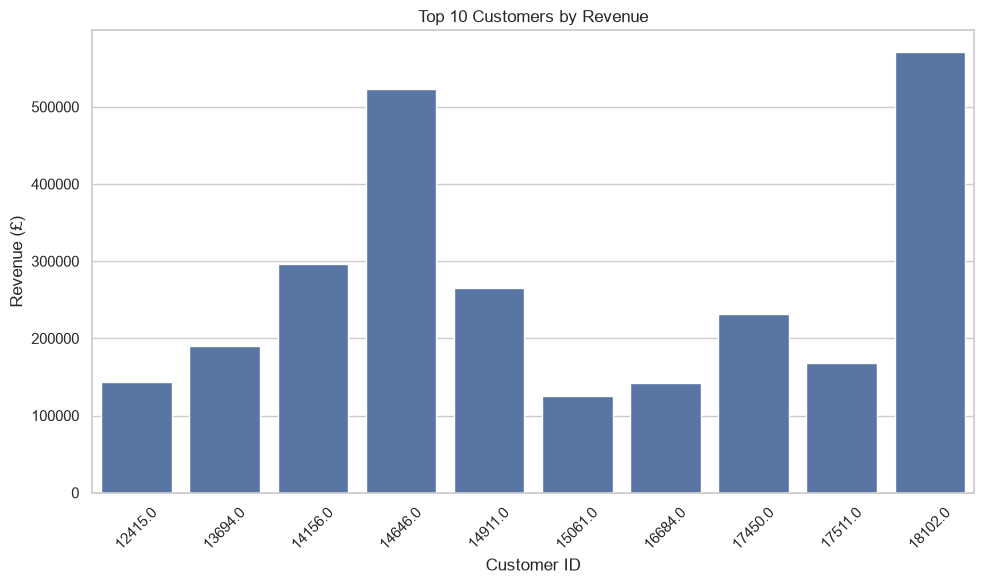

In [33]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=customer_revenue,
    x="Customer ID",
    y="Revenue"
)

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Customer ID")
plt.ylabel("Revenue (£)")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

## 13. Cancellation and Return Analysis

Cancellations, returns, and adjustments are analyzed to understand their impact on the business.

These records are retained because they represent meaningful business events rather than simply being treated as data errors.

In [34]:
transaction_summary = (
    df.groupby("TransactionType")
    .agg(
        Transactions=("Invoice", "count"),
        Revenue=("Revenue", "sum")
    )
    .reset_index()
)

transaction_summary

,TransactionType,Transactions,Revenue
0,Adjustment,3393,0.00
1,Cancellation/Return,19104,"-1,462,050.61"
2,Sale,1010534,"20,476,260.45"


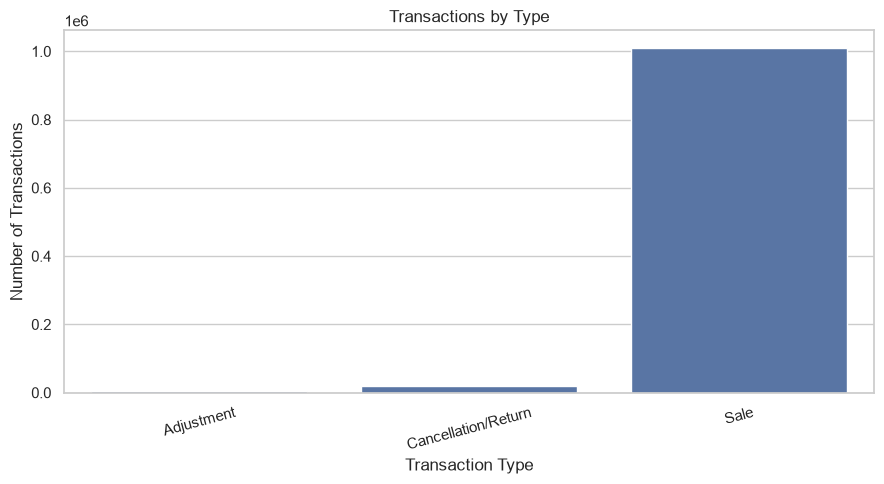

In [35]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=transaction_summary,
    x="TransactionType",
    y="Transactions"
)

plt.title("Transactions by Type")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")

plt.xticks(rotation=15)
plt.tight_layout()

plt.show()

In [36]:
non_sale_revenue = (
    df.loc[
        df['TransactionType'] != 'Sale',
        "Revenue"
    ].sum()
)

print(f"Revenue impact from cancellation/adjustments: £{non_sale_revenue:,.2f}")

Revenue impact from cancellation/adjustments: £-1,462,050.61


## 14. Revenue Outlier Analysis

The Interquartile Range (IQR) method is used to identify unusually high transaction revenue values.

These observations are treated as potential anomalies for investigation rather than automatically being removed.

In [37]:
Q1 = df["Revenue"].quantile(0.25)
Q3 = df["Revenue"].quantile(0.75)

IQR = Q3 - Q1

upper_bound = Q3 + (1.5 * IQR)

high_value_transactions = df[
    df["Revenue"] > upper_bound
]

print(f"Q1: £{Q1:,.2f}")
print(f"Q3: £{Q3:,.2f}")
print(f"IQR: £{IQR:,.2f}")
print(f"Upper Bound: £{upper_bound:,.2f}")
print(
    f"Potential high-value transactions: "
    f"{len(high_value_transactions):,}"
)

Q1: £3.75
Q3: £17.70
IQR: £13.95
Upper Bound: £38.63
Potential high-value transactions: 83,911


## 15. Key Insight Evidence

The following metrics are calculated to support the business insights presented in the final section.

Insights will be based on the actual results obtained from the dataset rather than assumptions.

In [38]:
# Top country by revenue
top_country = country_revenue.iloc[0]

# Top product by revenue
top_product = top_products_revenue.iloc[0]

# Top customer by revenue
top_customer = customer_revenue.iloc[0]

# Peak revenue month
peak_month = monthly_revenue.loc[
    monthly_revenue["Revenue"].idxmax()
]

# Total revenue
total_revenue = df["Revenue"].sum()

# Sales revenue
sales_revenue = df.loc[
    df["TransactionType"] == "Sale",
    "Revenue"
].sum()

print("KEY EVIDENCE")
print("=" * 50)

print(
    f"Top country by revenue: "
    f"{top_country['Country']} "
    f"(£{top_country['Revenue']:,.2f})"
)

print(
    f"Top product by revenue: "
    f"{top_product['Description']} "
    f"(£{top_product['Revenue']:,.2f})"
)

print(
    f"Top customer by revenue: "
    f"{int(top_customer['Customer ID'])} "
    f"(£{top_customer['Revenue']:,.2f})"
)

print(
    f"Peak revenue month: "
    f"{peak_month['YearMonth']} "
    f"(£{peak_month['Revenue']:,.2f})"
)

print(f"Total net revenue: £{total_revenue:,.2f}")
print(f"Total sales revenue: £{sales_revenue:,.2f}")

KEY EVIDENCE
Top country by revenue: United Kingdom (£16,144,736.48)
Top product by revenue: REGENCY CAKESTAND 3 TIER (£314,045.02)
Top customer by revenue: 18102 (£570,380.61)
Peak revenue month: 2011-11 (£1,456,145.80)
Total net revenue: £19,014,209.84
Total sales revenue: £20,476,260.45


## 16. Key Business Insights

Based on the exploratory analysis, the following key findings were identified:

1. **[Finding based on the actual revenue analysis]**

2. **[Finding based on the monthly trend]**

3. **[Finding based on top products]**

4. **[Finding based on country analysis]**

5. **[Finding based on customer analysis]**

6. **[Finding based on cancellations/returns or anomalies]**

## 17. Conclusion

The Exploratory Data Analysis provided an overall understanding of the Online Retail II dataset.

The analysis examined revenue trends, product performance, geographic distribution, customer contribution, transaction types, cancellations, and potential high-value anomalies.

The findings generated from this analysis can be used to support business decision-making and provide a foundation for the next stage of the internship project: developing an interactive dashboard.

## 18. Export Analysis Results

The main analysis results are exported as CSV files so that they can be reused for reporting, visualization, and the next stage of the project.

In [39]:
yearly_revenue.to_csv(
    "../output/yearly_revenue.csv",
    index=False
)

print("Saved: yearly_revenue.csv")

Saved: yearly_revenue.csv


In [40]:
monthly_revenue.to_csv(
    "../output/monthly_revenue.csv",
    index=False
)

print("Saved: monthly_revenue.csv")

Saved: monthly_revenue.csv


In [41]:
top_products_revenue.to_csv(
    "../output/top_products_revenue.csv",
    index=False
)

print("Saved: top_products_revenue.csv")

Saved: top_products_revenue.csv


In [42]:
top_products_quantity.to_csv(
    "../output/top_products_quantity.csv",
    index=False
)

print("Saved: top_products_quantity.csv")

Saved: top_products_quantity.csv


In [44]:
customer_revenue.to_csv(
    "../output/customer_revenue.csv",
    index=False
)

print("Saved: customer_revenue.csv")

Saved: customer_revenue.csv


In [43]:
transaction_summary.to_csv(
    "../output/transaction_summary.csv",
    index=False
)

print("Saved: transaction_summary.csv")

Saved: transaction_summary.csv


## 19. Save Visualizations

The key visualizations generated during EDA are saved as image files for documentation and future use.

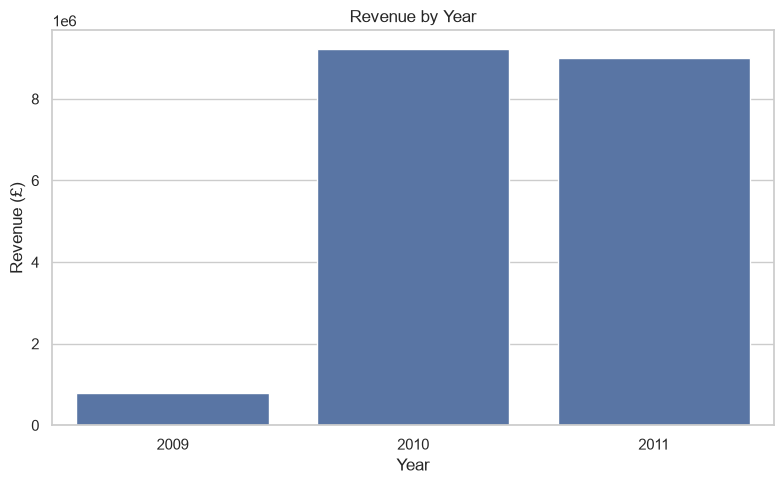

In [45]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=yearly_revenue,
    x="Year",
    y="Revenue"
)

plt.title("Revenue by Year")
plt.xlabel("Year")
plt.ylabel("Revenue (£)")
plt.tight_layout()

plt.savefig(
    "../visualizations/revenue_by_year.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

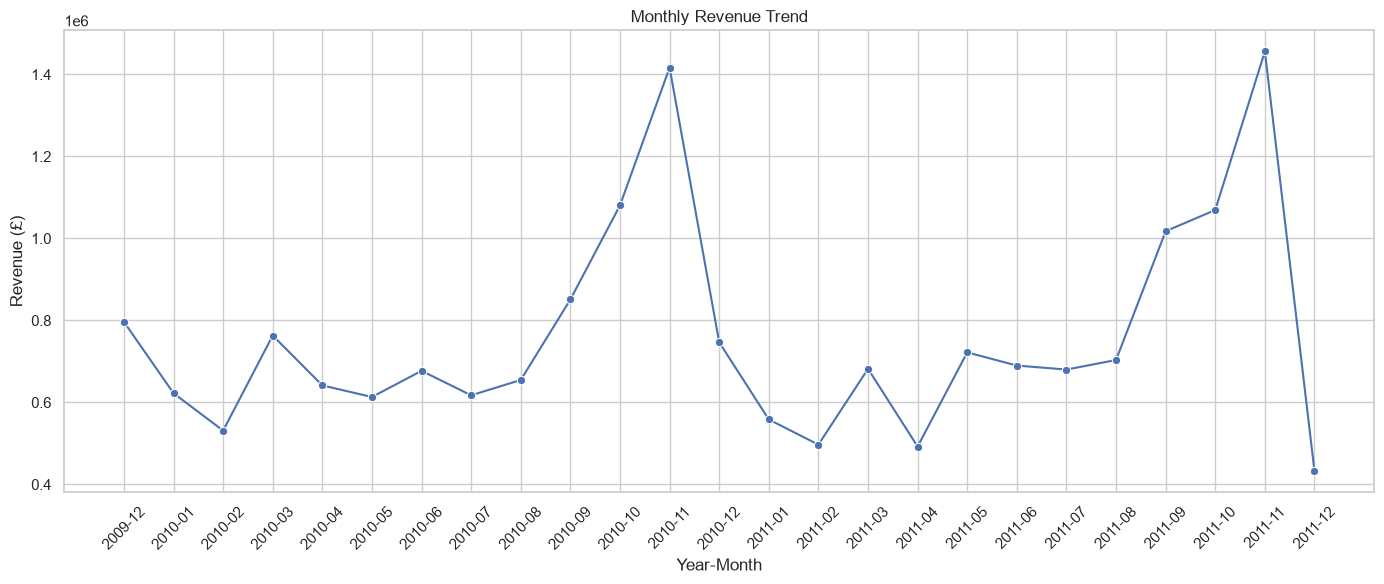

In [46]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_revenue,
    x="YearMonth",
    y="Revenue",
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Year-Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "../visualizations/monthly_revenue_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

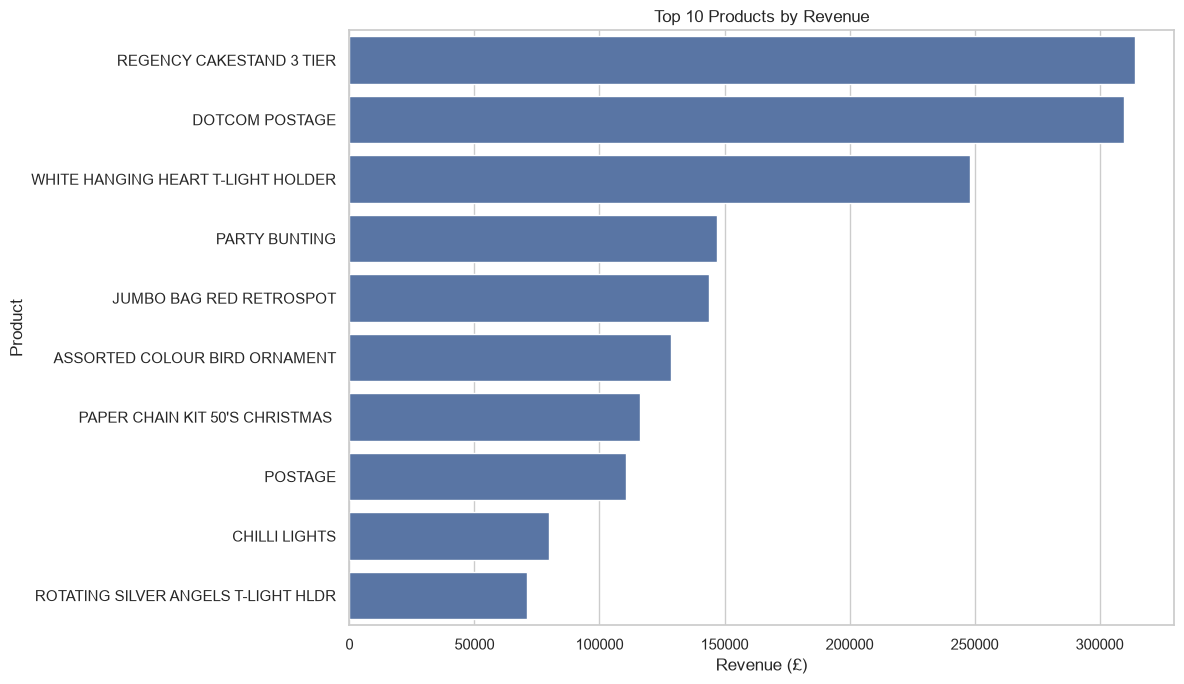

In [47]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_products_revenue,
    y="Description",
    x="Revenue"
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")

plt.tight_layout()

plt.savefig(
    "../visualizations/top_products_by_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

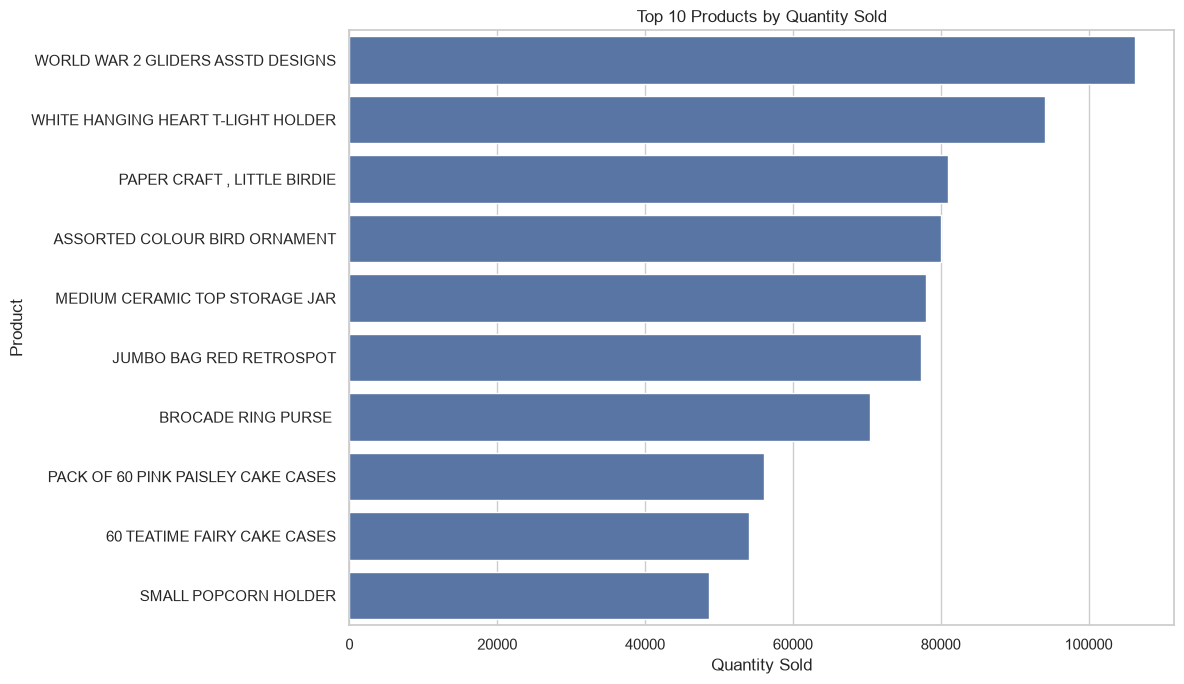

In [48]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_products_quantity,
    y="Description",
    x="Quantity"
)

plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Quantity Sold")
plt.ylabel("Product")

plt.tight_layout()

plt.savefig(
    "../visualizations/top_products_by_quantity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

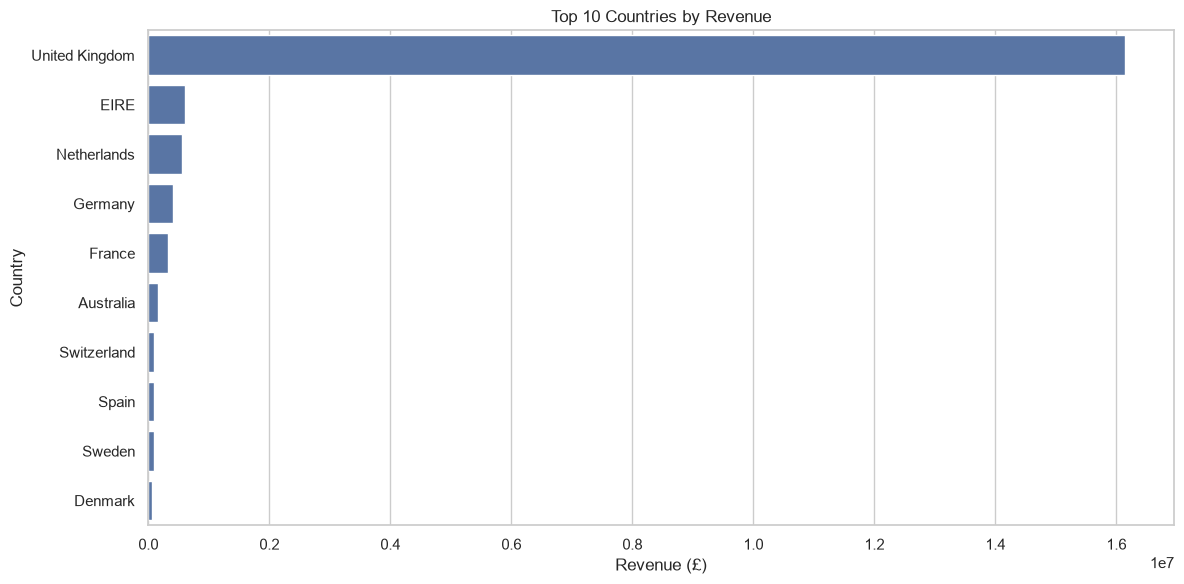

In [50]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=country_revenue,
    y="Country",
    x="Revenue"
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")

plt.tight_layout()

plt.savefig(
    "../visualizations/top_countries_by_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

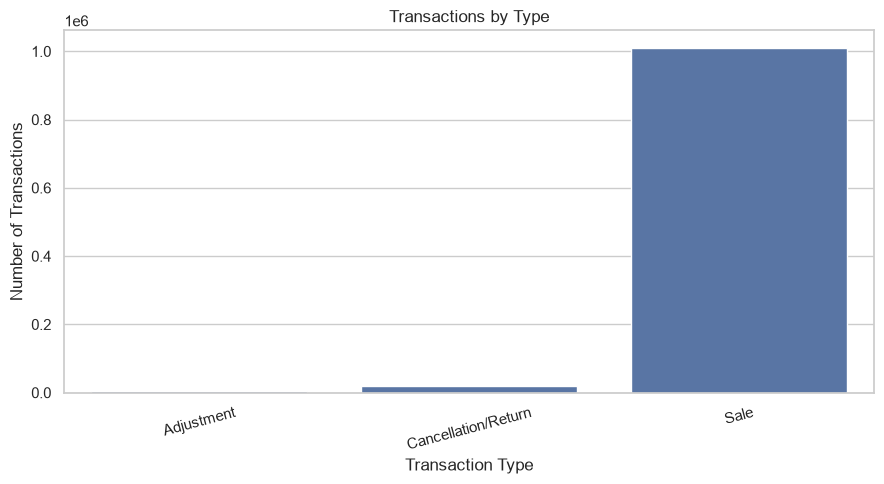

In [51]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=transaction_summary,
    x="TransactionType",
    y="Transactions"
)

plt.title("Transactions by Type")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")

plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    "../visualizations/transaction_type_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 20. EDA Summary

A summary table is created to capture the major metrics identified during the exploratory analysis.

In [52]:
eda_summary = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Total Columns",
        "Net Revenue",
        "Sales Revenue",
        "Top Country by Revenue",
        "Top Product by Revenue",
        "Peak Revenue Month",
        "Potential High-Value Transactions"
    ],
    "Value": [
        f"{len(df):,}",
        f"{len(df.columns)}",
        f"£{net_revenue:,.2f}",
        f"£{sales_revenue:,.2f}",
        top_country["Country"],
        top_product["Description"],
        peak_month["YearMonth"],
        f"{len(high_value_transactions):,}"
    ]
})

eda_summary

,Metric,Value
0,Total Records,"1,033,031"
1,Total Columns,16
2,Net Revenue,"£19,014,209.84"
3,Sales Revenue,"£20,476,260.45"
4,Top Country by Revenue,United Kingdom
5,Top Product by Revenue,REGENCY CAKESTAND 3 TIER
6,Peak Revenue Month,2011-11
7,Potential High-Value Transactions,"83,911"


In [53]:
eda_summary.to_csv(
    "../output/eda_summary.csv",
    index=False
)

print("Saved: eda_summary.csv")

Saved: eda_summary.csv


# Conclusion

The Exploratory Data Analysis provided a detailed understanding of the Online Retail II dataset.

The analysis covered:

- Dataset structure and data quality
- Descriptive statistics
- Revenue performance
- Yearly and monthly revenue trends
- Product performance
- Geographic revenue distribution
- Customer contribution
- Cancellations and adjustments
- Potential high-value transaction anomalies

The analysis identified patterns and relationships that can support business decision-making.

The exported analysis tables and visualizations will also provide a foundation for the next stage of the SWYNEX internship project, where the insights can be presented through an interactive dashboard.

In [54]:
print("=" * 60)
print("TASK 2 — EDA FINAL VALIDATION")
print("=" * 60)

print(f"Dataset shape       : {df.shape}")
print(f"Duplicate records   : {df.duplicated().sum():,}")
print(f"Missing dates       : {df['InvoiceDate'].isna().sum():,}")
print(f"Total net revenue   : £{df['Revenue'].sum():,.2f}")
print(f"Number of products  : {df['StockCode'].nunique():,}")
print(f"Number of countries : {df['Country'].nunique():,}")
print(
    f"Customers identified: "
    f"{df['Customer ID'].nunique():,}"
)

print("=" * 60)
print("EDA analysis completed successfully.")
print("=" * 60)

TASK 2 — EDA FINAL VALIDATION
Dataset shape       : (1033031, 16)
Duplicate records   : 0
Missing dates       : 0
Total net revenue   : £19,014,209.84
Number of products  : 5,305
Number of countries : 43
Customers identified: 5,942
EDA analysis completed successfully.


## 16. Key Business Insights

Based on the exploratory analysis of 1,033,031 transaction records, the following key insights were identified:

### 1. Strong Geographic Concentration

The United Kingdom generated the highest sales revenue, contributing approximately £17.41 million. This represents roughly 91.6% of the total net revenue, indicating that the business was highly concentrated in the UK market.

### 2. Product Revenue Is Distributed Across Multiple Products

The top 10 products contributed approximately 10.12% of total product revenue. This indicates that revenue was not dominated by only a small number of products and was distributed across a broad product portfolio.

### 3. High-Value Customer Contribution

Customer ID 18102 generated the highest identified customer revenue of approximately £580,987. The top 10 customers collectively contributed approximately 16.04% of customer-attributed revenue, showing that a relatively small group of customers generated a meaningful share of sales.

### 4. Strong Seasonal Revenue Peak

November 2011 recorded the highest monthly net revenue, reaching approximately £1.46 million. This indicates a significant increase in business activity during this period and suggests the presence of seasonal purchasing patterns.

### 5. Potential High-Value Transactions Require Investigation

The IQR-based analysis identified 84,954 transactions as potential high-value revenue anomalies. These records were not automatically removed because an unusually high transaction may represent genuine bulk purchasing or other legitimate business activity.

### 6. "Manual" Requires Further Investigation

"Manual" appeared as the highest-revenue product entry, generating approximately £339,226. Because "Manual" may represent an operational or manually entered transaction rather than a conventional retail product, it should be investigated separately before treating it as a normal product-performance insight.

In [55]:
insight_summary = pd.DataFrame({
    "Insight": [
        "Top country by sales revenue",
        "Top country revenue",
        "Top 10 products revenue share",
        "Top customer",
        "Top customer revenue",
        "Top 10 customers revenue share",
        "Peak revenue month",
        "Peak monthly revenue",
        "Potential high-value anomaly records"
    ],
    "Value": [
        "United Kingdom",
        "£17,410,196.12",
        "10.12%",
        "18102",
        "£580,987.04",
        "16.04%",
        "2011-11",
        "£1,456,145.80",
        "84,954"
    ]
})

insight_summary

,Insight,Value
0,Top country by sales revenue,United Kingdom
1,Top country revenue,"£17,410,196.12"
2,Top 10 products revenue share,10.12%
3,Top customer,18102
4,Top customer revenue,"£580,987.04"
5,Top 10 customers revenue share,16.04%
6,Peak revenue month,2011-11
7,Peak monthly revenue,"£1,456,145.80"
8,Potential high-value anomaly records,"84,954"


In [56]:
insight_summary.to_csv(
    "../output/final_business_insights.csv",
    index=False
)

print("Saved: final_business_insights.csv")

Saved: final_business_insights.csv


### Investigation of the Highest-Revenue Product Entry

The highest-revenue product entry was "Manual". Since this description may represent manually entered transactions rather than a conventional retail product, its underlying records are examined before drawing a product-performance conclusion.

In [57]:
manual_records = df[
    df["Description"].astype(str).str.strip().str.lower() == "manual"
]

print(f"Number of Manual records: {len(manual_records):,}")
print(f"Total Manual revenue: £{manual_records['Revenue'].sum():,.2f}")

manual_records.head(20)

Number of Manual records: 1,392
Total Manual revenue: £-83,311.28


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,IsCancellation,IsZeroPrice,TransactionType,Revenue,Year,Month,MonthName,YearMonth
2661,489609,M,Manual,1,2009-12-01 14:50:00,4.00,NaN,United Kingdom,False,False,Sale,4.00,2009,12,December,2009-12
3016,C489651,M,Manual,-1,2009-12-01 16:48:00,5.10,"17,804.00",United Kingdom,True,False,Cancellation/Return,-5.10,2009,12,December,2009-12
5826,C489859,M,Manual,-1,2009-12-02 14:45:00,69.57,NaN,United Kingdom,True,False,Cancellation/Return,-69.57,2009,12,December,2009-12
9168,C490126,M,Manual,-1,2009-12-03 18:12:00,5.95,"15,884.00",United Kingdom,True,False,Cancellation/Return,-5.95,2009,12,December,2009-12
9215,C490129,M,Manual,-1,2009-12-03 18:26:00,"1,998.49","15,482.00",United Kingdom,True,False,Cancellation/Return,"-1,998.49",2009,12,December,2009-12
11193,490300,M,Manual,1,2009-12-04 14:19:00,0.85,"12,970.00",United Kingdom,False,False,Sale,0.85,2009,12,December,2009-12
11194,490300,M,Manual,1,2009-12-04 14:19:00,0.21,"12,970.00",United Kingdom,False,False,Sale,0.21,2009,12,December,2009-12
15906,490727,M,Manual,1,2009-12-07 16:38:00,0.00,"17,231.00",United Kingdom,False,True,Sale,0.00,2009,12,December,2009-12
17072,C490748,M,Manual,-1,2009-12-07 18:14:00,309.73,"12,748.00",United Kingdom,True,False,Cancellation/Return,-309.73,2009,12,December,2009-12
17185,490760,M,Manual,1,2009-12-08 09:49:00,10.00,"14,295.00",United Kingdom,False,False,Sale,10.00,2009,12,December,2009-12


In [58]:
manual_records[
    [
        "Invoice",
        "StockCode",
        "Description",
        "Quantity",
        "InvoiceDate",
        "Price",
        "Customer ID",
        "Country",
        "TransactionType",
        "Revenue"
    ]
]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TransactionType,Revenue
2661,489609,M,Manual,1,2009-12-01 14:50:00,4.00,NaN,United Kingdom,Sale,4.00
3016,C489651,M,Manual,-1,2009-12-01 16:48:00,5.10,"17,804.00",United Kingdom,Cancellation/Return,-5.10
5826,C489859,M,Manual,-1,2009-12-02 14:45:00,69.57,NaN,United Kingdom,Cancellation/Return,-69.57
9168,C490126,M,Manual,-1,2009-12-03 18:12:00,5.95,"15,884.00",United Kingdom,Cancellation/Return,-5.95
9215,C490129,M,Manual,-1,2009-12-03 18:26:00,"1,998.49","15,482.00",United Kingdom,Cancellation/Return,"-1,998.49"
...,...,...,...,...,...,...,...,...,...,...
1022637,580956,M,Manual,4,2011-12-06 14:23:00,1.25,"17,841.00",United Kingdom,Sale,5.00
1024275,C581009,M,Manual,-1,2011-12-07 09:15:00,125.00,"16,971.00",United Kingdom,Cancellation/Return,-125.00
1025487,C581145,M,Manual,-1,2011-12-07 13:48:00,9.95,"17,490.00",United Kingdom,Cancellation/Return,-9.95
1029468,581405,M,Manual,3,2011-12-08 13:50:00,0.42,"13,521.00",United Kingdom,Sale,1.26


In [59]:
anomaly_summary = high_value_transactions[
    [
        "Invoice",
        "StockCode",
        "Description",
        "Quantity",
        "Price",
        "Country",
        "TransactionType",
        "Revenue"
    ]
].sort_values(
    "Revenue",
    ascending=False
)

anomaly_summary.head(20)

,Invoice,StockCode,Description,Quantity,Price,Country,TransactionType,Revenue
1031549,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,United Kingdom,Sale,"168,469.60"
557397,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,United Kingdom,Sale,"77,183.60"
717207,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,649.50,United Kingdom,Sale,"38,970.00"
238928,512771,M,Manual,1,"25,111.09",United Kingdom,Sale,"25,111.09"
426968,530715,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,9360,1.69,United Kingdom,Sale,"15,818.40"
511148,537632,AMAZONFEE,AMAZON FEE,1,"13,541.33",United Kingdom,Sale,"13,541.33"
794036,A563185,B,Adjust bad debt,1,"11,062.06",United Kingdom,Sale,"11,062.06"
133501,502265,M,Manual,1,"10,953.50",United Kingdom,Sale,"10,953.50"
133499,502263,M,Manual,1,"10,953.50",United Kingdom,Sale,"10,953.50"
338132,522796,M,Manual,1,"10,468.80",United Kingdom,Sale,"10,468.80"


In [60]:
print(
    f"Potential high-value anomalies: "
    f"{len(high_value_transactions):,}"
)

print(
    f"Percentage of dataset: "
    f"{len(high_value_transactions) / len(df) * 100:.2f}%"
)

Potential high-value anomalies: 83,911
Percentage of dataset: 8.12%


In [61]:
high_value_transactions.to_csv(
    "../output/high_value_anomalies.csv",
    index=False
)

print("Saved: high_value_anomalies.csv")

Saved: high_value_anomalies.csv


# Final EDA Summary

The Exploratory Data Analysis successfully examined the cleaned Online Retail II dataset containing 1,033,031 records across 16 variables.

The analysis covered data quality, descriptive statistics, revenue trends, product performance, geographic distribution, customer contribution, transaction types, cancellations and potential revenue anomalies.

The analysis found that the United Kingdom was the dominant sales market, November 2011 was the peak revenue month, and a relatively small group of customers contributed a significant portion of customer-attributed revenue.

The analysis also identified potential high-value transactions and an unusual "Manual" product entry that requires further investigation rather than being automatically classified as a conventional top-performing product.

All major analysis tables and visualizations have been exported to the project output and visualizations folders for reproducibility and future use.